# OpenCV: Face Detection with Haar Cascade

In the previous notebooks, you read images and live webcam frames. Now you'll **detect faces** in an image using a **pre-trained Haar Cascade classifier**.

**Workflow:** Load the Haar Cascade model (`cv2.CascadeClassifier()`) → Read the image (`cv2.imread()`) → Detect faces (`detectMultiScale()`) → Draw rectangles (`cv2.rectangle()`) → Display the result (`cv2.imshow()`)

## 1. Load the pre-trained Haar Cascade model

OpenCV provides a pre-trained XML file containing information for detecting frontal faces. Here we use `haarcascade_frontalface_default.xml`.

- `CascadeClassifier()` loads the trained classifier.
- The XML file contains learned detection information.
- Because this is a **frontal-face** classifier, it is designed primarily to detect faces facing forward.

The model is already trained. You don't need to train it yourself for this example.

In [1]:
import cv2

model = cv2.CascadeClassifier("haarcascade_frontalface_default.xml")

if model.empty():
    raise FileNotFoundError("Could not load the cascade XML file")

## 2. Read the image

OpenCV reads the image and stores its pixel values in a NumPy array.

In [2]:
image = cv2.imread("faces.jpg")

if image is None:
    raise FileNotFoundError("Could not read the image")

## 3. Detect faces

This is the main step. `detectMultiScale()` returns the detected face rectangles. Each rectangle contains four values: $(x, y, w, h)$

| Value | Meaning |
|---|---|
| `x` | Horizontal position of the rectangle's top-left corner |
| `y` | Vertical position of the top-left corner |
| `w` | Width of the detected face rectangle |
| `h` | Height of the detected face rectangle |

In [3]:
faces = model.detectMultiScale(
    image,
    scaleFactor=1.3,
    minNeighbors=5
)

print("Number of faces detected:", len(faces))
print(faces)

Number of faces detected: 7
[[ 42  29  64  64]
 [263  68  60  60]
 [148 110  57  57]
 [209 136  59  59]
 [  3 122  59  59]
 [318 136  74  74]
 [ 70 117  63  63]]


## 4. Understand the two important parameters

### `scaleFactor=1.3`
The detector examines image regions at progressively different scales. A value of `1.3` means each successive image scale is reduced by a factor of approximately 1.3. A **smaller** value generally checks more scales, which can improve detection of differently sized faces but may take longer.

### `minNeighbors=5`
Controls how many nearby overlapping detection candidates are needed for a rectangle to be retained.

- **Higher value:** usually fewer detections, with stricter filtering.
- **Lower value:** usually more detections, but potentially more false positives.

These are **hyperparameters** you can tune to suit your images.

## 5. Draw a rectangle around each face

The rectangle function needs two corners:

- First corner (top-left): `(x, y)`
- Opposite corner (bottom-right): `(x + w, y + h)`

The color `(0, 255, 0)` is **green** in OpenCV's BGR format, and `2` is the line thickness in pixels.

In [4]:
output = image.copy()  # keep the original input image unchanged

for (x, y, w, h) in faces:
    cv2.rectangle(
        output,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

## 6. Display the input and output images

We use **matplotlib** to show both images side by side, right inside the notebook.

OpenCV stores images in **BGR** order, but matplotlib expects **RGB**, so we convert with `cv2.cvtColor(..., cv2.COLOR_BGR2RGB)` before displaying.

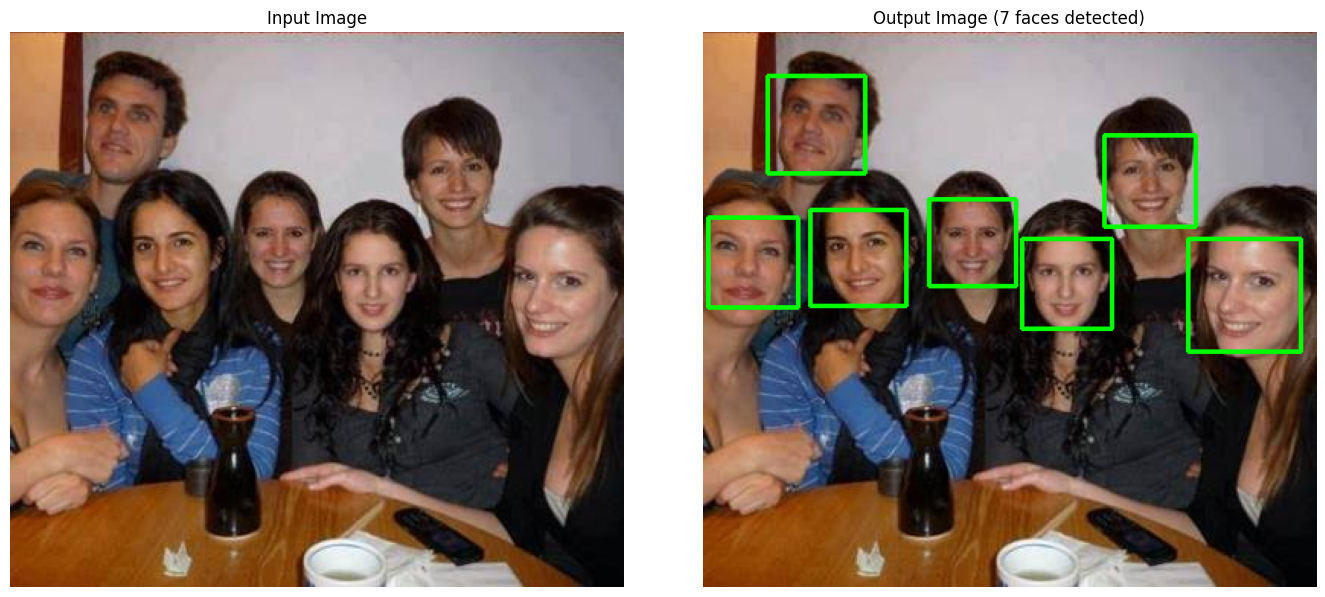

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title(f"Output Image ({len(faces)} faces detected)")
plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Complete code

Number of faces detected: 7


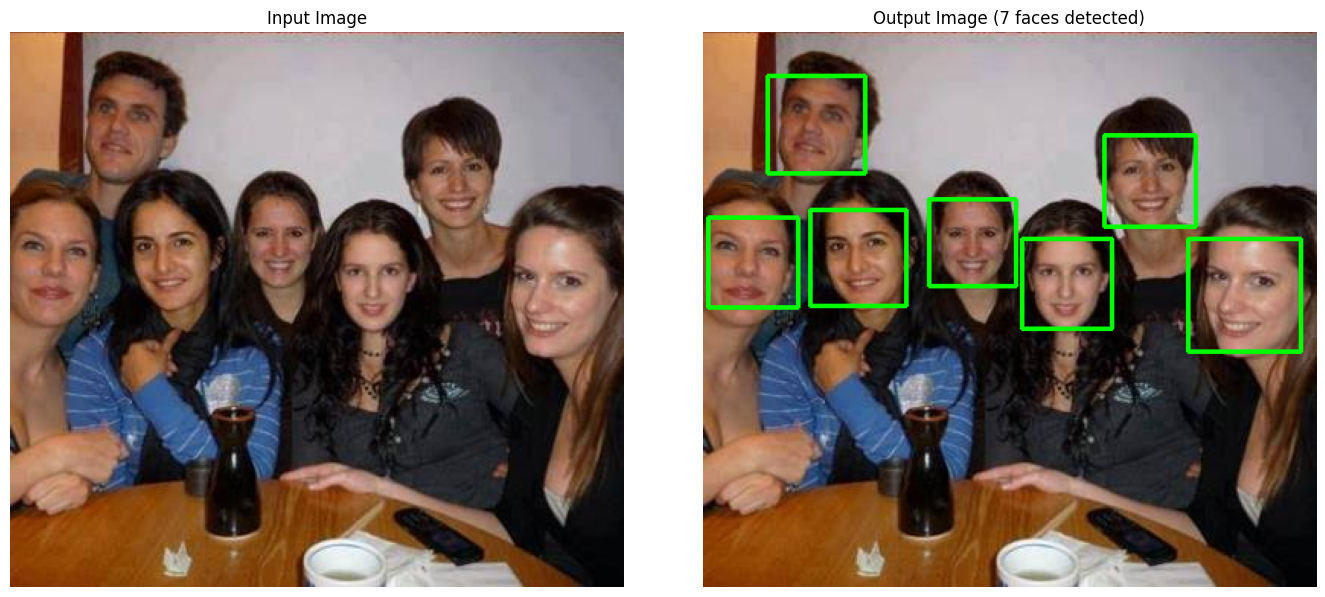

In [ ]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread("faces.jpg")
model = cv2.CascadeClassifier("haarcascade_frontalface_default.xml")

if image is None:
    raise FileNotFoundError("Could not read the image")

if model.empty():
    raise FileNotFoundError("Could not load the cascade XML file")

faces = model.detectMultiScale(
    image,
    scaleFactor=1.3,
    minNeighbors=5
)

print("Number of faces detected:", len(faces))

output = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        output,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
plt.title(f"Output Image ({len(faces)} faces detected)")
plt.axis("off")

plt.tight_layout()
plt.show()